# Clustering de documents

## Imports

In [29]:
import collections
import os
import string
import sys

import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

In [30]:
import nltk

nltk.download('punkt')
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\asusz\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\asusz\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [31]:
data_path = "../data/txt/"

## Choisir une décennie

In [32]:
DECADE = '1950' #c'est à dire on va choisir tous les textes dont le titre commence par "195-"

## Charger tous les  fichiers de la décennie et en créer une liste de textes

In [33]:
files = [f for f in sorted(os.listdir(data_path)) if f"_{DECADE[:-1]}" in f]

In [34]:
# Exemple de fichiers
files[:5]

['KB_JB838_1950-01-06_01-00002.txt',
 'KB_JB838_1950-01-07_01-00013.txt',
 'KB_JB838_1950-01-08_01-00011.txt',
 'KB_JB838_1950-01-10_01-00006.txt',
 'KB_JB838_1950-01-15_01-00010.txt']

In [35]:
texts = [open(data_path + f, "r", encoding="utf-8").read() for f in files]

In [36]:
# Exemple de textes
texts[0][:400]

'/ LE SOIR Une importante manifestation franco-belge Le Comité franco-belge du Commerce, de l’Industrie et de l’Agriculture qui. au cours de l’année écoulée et dans les circonstances les plus difficiles a rendu aux relations économiques entre les deux pays des services considérables, donnera le 12 janvier, à 19 h. 30, un dîner à l’occasion de l’anniversaire de son installation. Ce comité, qui fonct'

## Vectoriser les documents à l'aide de TF-IDF

In [37]:
# Création d'une fonction de pré-traitement tout à l'heure on a fait ce pre-traitement à l'aide de tf-idf
def preprocessing(text, stem=True):
    """ Tokenize text and remove punctuation """
    text = text.translate(string.punctuation)
    tokens = word_tokenize(text)
    return tokens

### Instancier le modèle TF-IDF avec ses arguments

In [38]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

### Construire la matrice de vecteurs à l'aide de la fonction `fit_transform`

In [39]:
tfidf_vectors = vectorizer.fit_transform(texts) #fit calcule le poids de tf-idf dans chaque document, transfrom: entraine le modèle sur un corpus sans prendre les vecteurs (donc la matrice) et on peut ensuite utiliser ce modèle entrainé sur un autre campus sans que ça soit influencé par le premier

c:\Users\asusz\tac\.venv\Lib\site-packages\sklearn\feature_extraction\text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [40]:
# Détail de la matrice
tfidf_vectors

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 705959 stored elements and shape (1000, 3518)>

### Imprimer le vecteur tf-IDF du premier document

In [41]:
#le but c'est de trouver c'est quoi le mot le plus sayant
pd.Series(
    tfidf_vectors[0].toarray()[0],
    index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

parti           0.276380
loyer           0.151870
janvier         0.147707
populaire       0.146856
propriétaire    0.143376
                  ...   
ù               0.000000
étalent         0.000000
étages          0.000000
étage           0.000000
ï               0.000000
Length: 3518, dtype: float64

## Comprendre les vecteurs et leurs "distances"

In [42]:
cosine([1, 2, 3], [1, 2, 3])

np.float64(0.0)

In [43]:
cosine([1, 2, 3], [1, 2, 2])

np.float64(0.02004211298777725)

In [44]:
cosine([1, 2, 3], [2, 2, 2])

np.float64(0.07417990022744858)

### Tests sur nos documents

In [45]:
tfidf_array = tfidf_vectors.toarray()

In [46]:
# Vecteur du document 0
tfidf_array[0]

array([0.        , 0.        , 0.        , ..., 0.        , 0.        ,
       0.03765185], shape=(3518,))

In [47]:
# Vecteur du document 1
tfidf_array[1]

array([0.        , 0.00671156, 0.        , ..., 0.        , 0.        ,
       0.        ], shape=(3518,))

In [48]:
cosine(tfidf_array[0], tfidf_array[1])

np.float64(0.9313499929129303)

## Appliquer un algorithme de clustering sur les vecteurs TF-IDF des documents

Pour en savoir plus sur le KMeans clustering :
- https://medium.com/dataseries/k-means-clustering-explained-visually-in-5-minutes-b900cc69d175

### Définir un nombre de clusters (c'est le modèle de K-Means), ici on définit la valeur de K

In [49]:
N_CLUSTERS = 4

### Instancier le modèle K-Means et ses arguments

In [50]:
km_model = KMeans(n_clusters=N_CLUSTERS)

### Appliquer le clustering à l'aide de la fonction `fit_predict`

In [51]:
clusters = km_model.fit_predict(tfidf_vectors)

In [52]:
clustering = collections.defaultdict(list)

for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

In [53]:
pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1950-01-07_01-00013.txt',
               'KB_JB838_1950-01-08_01-00011.txt',
               'KB_JB838_1950-02-15_01-00014.txt',
               'KB_JB838_1950-02-16_01-00014.txt',
               'KB_JB838_1950-02-18_01-00014.txt',
               'KB_JB838_1950-02-25_01-00013.txt',
               'KB_JB838_1950-02-28_01-00012.txt',
               'KB_JB838_1950-03-03_01-00013.txt',
               'KB_JB838_1950-03-15_01-00012.txt',
               'KB_JB838_1950-03-29_01-00008.txt',
               'KB_JB838_1950-04-21_01-00010.txt',
               'KB_JB838_1950-04-25_01-00011.txt',
               'KB_JB838_1950-05-24_01-00014.txt',
               'KB_JB838_1950-06-04_01-00012.txt',
               'KB_JB838_1950-06-14_01-00014.txt',
               'KB_JB838_1950-06-24_01-00011.txt',
               'KB_JB838_1950-06-25_01-00013.txt',
               'KB_JB838_1950-07-02_01-00018.txt',
               'KB_JB838_1950-07-08_01-00009.txt',
               'KB_JB838_1950-0

## Visualiser les clusters

### Réduire les vecteurs à 2 dimensions à l'aide de l'algorithme PCA
Cette étape est nécessaire afin de visualiser les documents dans un espace 2D

https://fr.wikipedia.org/wiki/Analyse_en_composantes_principales

In [54]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

In [55]:
reduced_vectors[:10]

array([[-0.32600408,  0.11380766],
       [ 0.11292559, -0.29966194],
       [ 0.44320535, -0.2536241 ],
       [-0.23929268, -0.03769739],
       [-0.05196042, -0.10674476],
       [ 0.61308801,  0.50410236],
       [-0.20306019, -0.03730042],
       [-0.19473166, -0.03762281],
       [ 0.6241313 ,  0.45593668],
       [ 0.15590694, -0.01392228]])

### Générer le plot

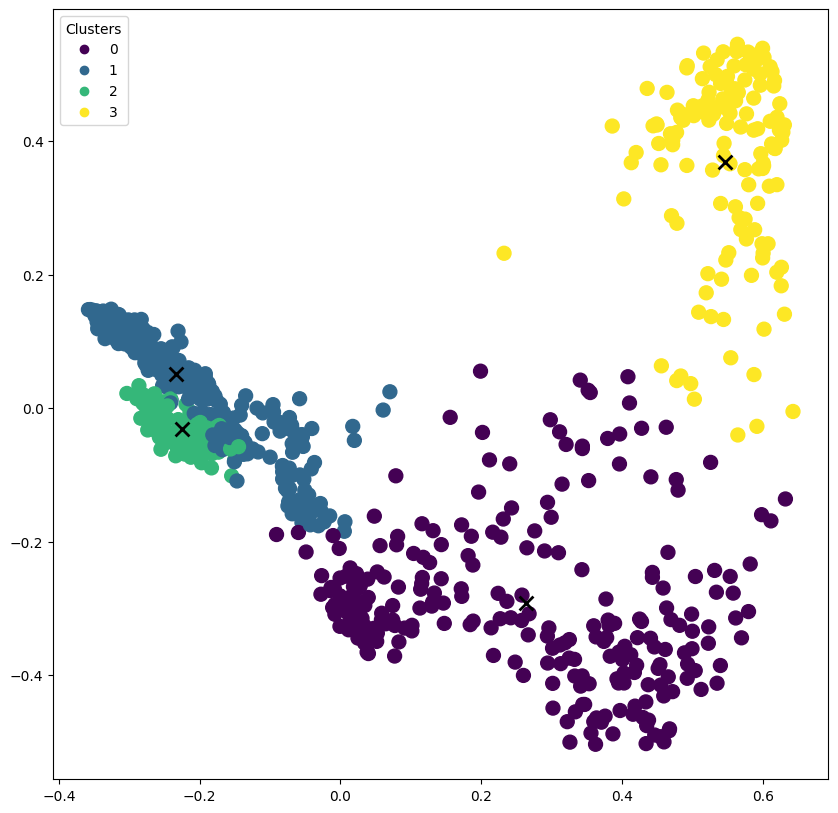

In [56]:
x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")